# Phase 1: Data Loading & Cleaning

In [ ]:
# Import the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files

uploaded = files.upload()

# load the uploaded file into a dataframe
df = pd.read_excel('Case_Study_Data.xlsx')

Saving Case_Study_Data.xlsx to Case_Study_Data (1).xlsx


In [ ]:
# preview the first five rows
df.head()

,Month,Account ID,User ID,Job Ad (Role) ID,Sessions,Message Sends,Job Sends,CVs Accessed,Message Credits Used,Send Job Credits Used,Access CV Credits Used,Total Credits Used
0,2014-11-01,82843835,115281,32323619,2,0,0,0,0,0,0,0
1,2014-11-01,82843835,115281,32375702,1,0,0,0,0,0,0,0
2,2014-11-01,87378708,173643,32385983,1,0,0,0,0,0,0,0
3,2014-11-01,82843835,115281,32415660,5,0,0,0,0,0,0,0
4,2014-11-01,86472783,808481,32421348,1,0,0,0,0,0,0,0


In [ ]:
# preview data from the bottom?
print("\nLast 5 rows:")
df.tail()


Last 5 rows:


,Month,Account ID,User ID,Job Ad (Role) ID,Sessions,Message Sends,Job Sends,CVs Accessed,Message Credits Used,Send Job Credits Used,Access CV Credits Used,Total Credits Used
1526,2015-01-01,6680812,887668,32034129,1,0,0,0,0,0,0,0
1527,2015-01-01,86808121,148484,32035722,1,0,0,4,0,0,2000,2000
1528,2015-01-01,86137806,886544,32038373,1,0,0,0,0,0,0,0
1529,2015-01-01,87378708,173643,32039573,1,0,0,0,0,0,0,0
1530,2015-01-01,83410767,150258,32041032,1,0,0,1,0,0,500,500


In [ ]:
df.rename(columns={
    'Month' : 'month',
    'Account ID' : 'account_id',
    'User ID' : 'user_id',
    'Job Ad (Role) ID' : 'job_ad_id',
    'Sessions' : 'sessions',
    'Message Sends' : 'msg_sends',
    'Job Sends' : 'job_sends',
    'CVs Accessed' : 'cv_accessed',
    'Message Credits Used' : 'msg_credits',
    'Send Job Credits Used' : 'job_credits',
    'Access CV Credits Used' : 'cv_credits',
    'Total Credits Used' : 'total_credits'
}, inplace=True)

# confirm the new column names
print(df.columns.tolist())

['month', 'account_id', 'user_id', 'job_ad_id', 'sessions', 'msg_sends', 'job_sends', 'cv_accessed', 'msg_credits', 'job_credits', 'cv_credits', 'total_credits']


In [ ]:
df.describe()

,month,account_id,user_id,job_ad_id,sessions,msg_sends,job_sends,cv_accessed,msg_credits,job_credits,cv_credits,total_credits
count,1531,1531.00,1531.00,1531.00,1531.00,1531.00,1531.00,1531.00,1531.00,1531.00,1531.00,1531.00
mean,2014-12-05 08:03:26.923579392,56880210.48,5172555.20,31238174.52,1.66,0.13,0.59,3.51,25.60,58.72,1756.04,1840.37
min,2014-11-01 00:00:00,41.00,18.00,32.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2014-11-01 00:00:00,14051572.00,136842.00,32640288.50,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,2014-12-01 00:00:00,82878850.00,181372.00,32736611.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,2015-01-01 00:00:00,86808121.00,805765.00,32966926.00,2.00,0.00,0.00,1.00,0.00,0.00,500.00,500.00
max,2015-01-01 00:00:00,88802886.00,87862517.00,33297859.00,80.00,16.00,79.00,100.00,3200.00,7900.00,50000.00,50200.00
std,NaN,36329316.70,19362233.56,6997778.70,2.85,0.93,3.16,15.26,185.83,316.47,7627.68,7640.37


In [ ]:
# numbers rows and columns
print("Shape:", df.shape)

Shape: (1531, 12)


In [ ]:
# column names and data types
print("\nColumn info:")
print(df.dtypes)


Column info:
month            datetime64[ns]
account_id                int64
user_id                   int64
job_ad_id                 int64
sessions                  int64
msg_sends                 int64
job_sends                 int64
cv_accessed               int64
msg_credits               int64
job_credits               int64
cv_credits                int64
total_credits             int64
dtype: object


In [ ]:
# basic dataset counts
print(f"Total rows        : {len(df)}")
print(f"Unique accounts   : {df['account_id'].nunique()}")
print(f"Unique users      : {df['user_id'].nunique()}")
print(f"Unique job ads    : {df['job_ad_id'].nunique()}")
print(f"Months covered    : {df['month'].unique()}")

Total rows        : 1531
Unique accounts   : 241
Unique users      : 507
Unique job ads    : 1288
Months covered    : <DatetimeArray>
['2014-11-01 00:00:00', '2014-12-01 00:00:00', '2015-01-01 00:00:00']
Length: 3, dtype: datetime64[ns]


#  Data Quality Checks

In [ ]:
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
month            0
account_id       0
user_id          0
job_ad_id        0
sessions         0
msg_sends        0
job_sends        0
cv_accessed      0
msg_credits      0
job_credits      0
cv_credits       0
total_credits    0
dtype: int64


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
numeric_cols = ['sessions','msg_sends','job_sends','cv_accessed',
                'msg_credits','job_credits','cv_credits','total_credits']

print("Negative values per column:")
print((df[numeric_cols] < 0).sum())

Negative values per column:
sessions         0
msg_sends        0
job_sends        0
cv_accessed      0
msg_credits      0
job_credits      0
cv_credits       0
total_credits    0
dtype: int64


In [ ]:
# message=200 credits, job send=100, cv access=500
df['credits_check'] = (df['msg_sends'] * 200 +
                       df['job_sends'] * 100 +
                       df['cv_accessed'] * 500)

mismatch = df[df['credits_check'] != df['total_credits']]
print("Rows where credit math doesn't match:", len(mismatch))

# drop the helper column after check
df.drop(columns=['credits_check'], inplace=True)

Rows where credit math doesn't match: 0


# Feature Engineering

In [ ]:
# month label for cleaner charts
# convert datetime to readable label e.g. "Nov 2014"

df['month_label'] = df['month'].dt.strftime('%b %Y')

In [ ]:
# connection made flag
# 1 if the user made any connection that row, 0 if not

df['connection_made'] = (df['total_credits'] > 0).astype(int)

In [ ]:
# total connections per row
# sum of all 3 connection types in each row

df['total_connections'] = df['msg_sends'] + df['job_sends'] + df['cv_accessed']

In [ ]:
# dominant connection method per row

# which connection type was used the most in each row
df['dominant_method'] = df[['msg_sends', 'job_sends', 'cv_accessed']].idxmax(axis=1)

# if no connections were made, label it as none
df.loc[df['total_connections'] == 0, 'dominant_method'] = 'none'

In [ ]:
# confirm new columns look correct

df[['month_label', 'connection_made', 'total_connections', 'dominant_method']].head(10)

,month_label,connection_made,total_connections,dominant_method
0,Nov 2014,0,0,none
1,Nov 2014,0,0,none
2,Nov 2014,0,0,none
3,Nov 2014,0,0,none
4,Nov 2014,0,0,none
5,Nov 2014,0,0,none
6,Nov 2014,0,0,none
7,Nov 2014,0,0,none
8,Nov 2014,0,0,none
9,Nov 2014,1,1,job_sends


# Phase 2: Analysis

#  1.Engagement Overview

In [ ]:
#  active vs passive accounts

total_accounts = df['account_id'].nunique()

active_accounts = df[df['connection_made'] == 1]['account_id'].nunique()
passive_accounts = total_accounts - active_accounts

print(f"Total accounts : {total_accounts}")
print(f"Active accounts : {active_accounts}")
print(f"Passive accounts : {passive_accounts}")
print(f"Engagement rate : {active_accounts / total_accounts * 100:.1f}%")

Total accounts : 241
Active accounts : 60
Passive accounts : 181
Engagement rate : 24.9%


In [ ]:
# active vs passive users

total_users = df['user_id'].nunique()

active_users = df[df['connection_made'] == 1]['user_id'].nunique()
passive_users = total_users - active_users

print(f"Total users : {total_users}")
print(f"Active users : {active_users}")
print(f"Passive users : {passive_users}")
print(f"User engagement rate : {active_users / total_users * 100:.1f}%")

Total users : 507
Active users : 171
Passive users : 336
User engagement rate : 33.7%


In [ ]:
# session to connection conversion rate

total_sessions = df['sessions'].sum()
total_connections = df['total_connections'].sum()

print(f"Total sessions : {total_sessions}")
print(f"Total connections made : {total_connections}")
print(f"Conversion rate : {total_connections / total_sessions * 100:.1f}%")

text = """\n
A 254% conversion rate is impossible in the real world.

Example: That user had 3 sessions but made 15 connections across
those sessions.

Sessions and connections are not directly comparable.

Sessions count logins. Connections count individual actions.
A user can send many messages in a single session.
"""

print(text)

Total sessions : 2547
Total connections made : 6472
Conversion rate : 254.1%


A 254% conversion rate is impossible in the real world.

Example: That user had 3 sessions but made 15 connections across
those sessions.

Sessions and connections are not directly comparable.

Sessions count logins. Connections count individual actions.
A user can send many messages in a single session.



In [ ]:
# rows where the user had at least one session
rows_with_sessions = df[df['sessions'] > 0]

# of those, how many also resulted in at least one connection
rows_with_connections = rows_with_sessions[rows_with_sessions['connection_made'] == 1]

conversion_rate = len(rows_with_connections) / len(rows_with_sessions) * 100

print(f"Rows with sessions : {len(rows_with_sessions)}")
print(f"Rows that led to a connection : {len(rows_with_connections)}")
print(f"Conversion rate : {conversion_rate:.1f}%")

text = """\nThe way this data was collected, a row only exists if a user had a session.
There are no rows for users who had zero sessions. So sessions and rows are essentially
the same thing here.

Hence, have to Keep it as an engagement rate and look at connections per session instead
Calculate the average number of connections a user makes per session
 """

print(text)

Rows with sessions : 1531
Rows that led to a connection : 505
Conversion rate : 33.0%

The way this data was collected, a row only exists if a user had a session.
There are no rows for users who had zero sessions. So sessions and rows are essentially
the same thing here.

Hence, have to Keep it as an engagement rate and look at connections per session instead
Calculate the average number of connections a user makes per session
 


In [ ]:
total_sessions = df['sessions'].sum()
total_connections = df['total_connections'].sum()

# only look at rows where connections were actually made
active_rows = df[df['connection_made'] == 1]
avg_connections_per_session = active_rows['total_connections'].sum() / active_rows['sessions'].sum()

print(f"Total sessions (all rows) : {total_sessions}")
print(f"Total connections made : {total_connections}")
print(f"Avg connections per session (active rows only) : {avg_connections_per_session:.1f}")

text = """\nWhen a user was actively making connections,
they made on average 6.2 connections per session.
This tells us that when hirers engaged, they engaged meaningfully.
they weren't just making one connection and leaving
"""

print(text)

Total sessions (all rows) : 2547
Total connections made : 6472
Avg connections per session (active rows only) : 6.2

When a user was actively making connections,
they made on average 6.2 connections per session.
This tells us that when hirers engaged, they engaged meaningfully.
they weren't just making one connection and leaving



In [ ]:
# active/passive colors (used in section 1 and reused where relevant)
COLOR_ACTIVE = '#2ecc71'
COLOR_PASSIVE = '#e74c3c'

# month order — ensures charts always show Nov → Dec → Jan
MONTH_ORDER = ['Nov 2014', 'Dec 2014', 'Jan 2015']

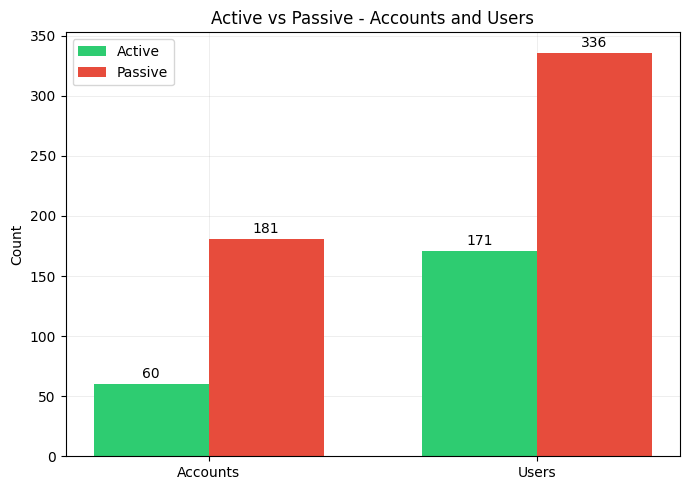

In [ ]:
# data for chart
categories = ['Accounts', 'Users']
active = [active_accounts, active_users]
passive = [passive_accounts, passive_users]

x = np.arange(len(categories))
width = 0.35

fig, ax = plt.subplots(figsize=(7, 5))

bars1 = ax.bar(x - width/2, active, width, label='Active', color='#2ecc71')
bars2 = ax.bar(x + width/2, passive, width, label='Passive', color='#e74c3c')

# add value labels on top of each bar
for bar in bars1 + bars2:
    ax.text(bar.get_x() + bar.get_width() / 2,
           bar.get_height() + 5,
           int(bar.get_height()),
           ha='center', fontsize=10)

ax.set_axisbelow(True)
ax.grid(True, which='major', axis='both', linestyle='-', linewidth=0.5, alpha=0.3)

ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylabel('Count')
ax.set_title('Active vs Passive - Accounts and Users')
ax.legend()
plt.tight_layout()
plt.show()

# 2.Connection Behaviour

In [ ]:
total_msg = df['msg_sends'].sum()
total_job = df['job_sends'].sum()
total_cv = df['cv_accessed'].sum()
total_all = total_msg + total_job + total_cv

print(f"Message Sends : {total_msg:,} ({total_msg/total_all*100:.1f}%)")
print(f"Job Sends : {total_job:,} ({total_job/total_all*100:.1f}%)")
print(f"CVs Accessed : {total_cv:,} ({total_cv/total_all*100:.1f}%)")
print(f"Total : {total_all:,}")

Message Sends : 196 (3.0%)
Job Sends : 899 (13.9%)
CVs Accessed : 5,377 (83.1%)
Total : 6,472


In [ ]:
# connection method colors - consistent across all charts
COLOR_MSG = '#3498db' # blue - message send
COLOR_JOB = '#f39c12' # amber - job send
COLOR_CV = '#9b59b6' # purple - cv access

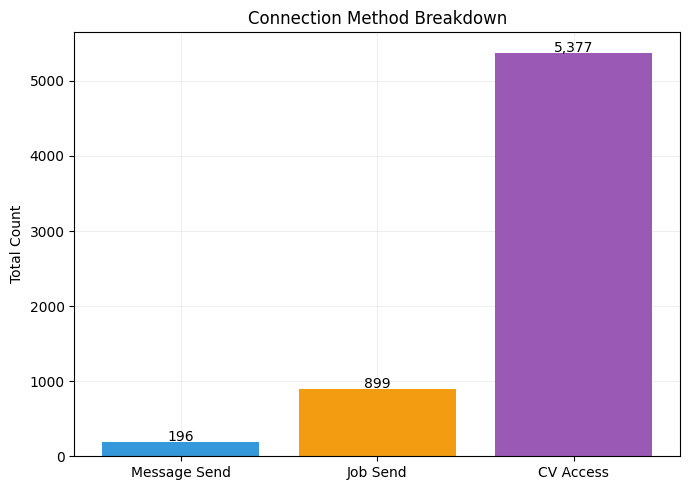

In [ ]:
# connection method breakdown

methods = ['Message Send', 'Job Send', 'CV Access']
counts = [total_msg, total_job, total_cv]
colors = [COLOR_MSG, COLOR_JOB, COLOR_CV]

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(methods, counts, color=colors)

for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2,
           bar.get_height() + 10,
           f'{int(bar.get_height()):,}',
           ha='center', fontsize=10)

ax.set_axisbelow(True)
ax.grid(True, which='major', axis='both', linestyle='-', linewidth=0.5, alpha=0.3)


ax.set_ylabel('Total Count')
ax.set_title('Connection Method Breakdown')
plt.tight_layout()
plt.show()

In [ ]:
# monthly breakdown by connection method

monthly = df.groupby('month_label')[['msg_sends', 'job_sends', 'cv_accessed']].sum()
monthly = monthly.reindex(MONTH_ORDER)

print(monthly)

             msg_sends  job_sends  cv_accessed
month_label                                   
Nov 2014            22        313          981
Dec 2014           106        260         2037
Jan 2015            68        326         2359


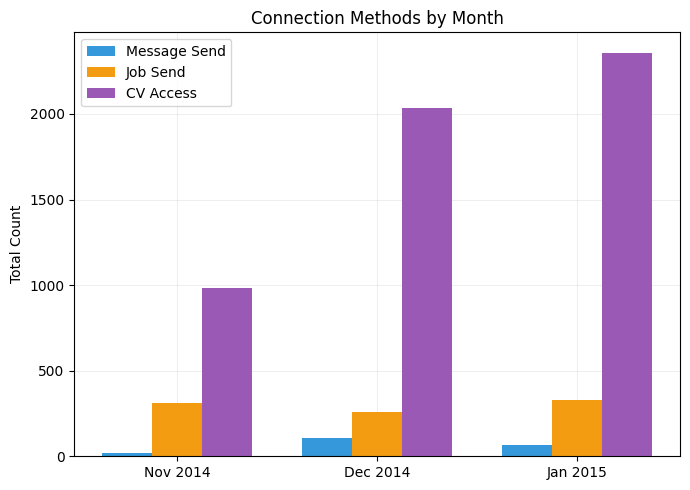

In [ ]:
#  monthly connection method trend

x = np.arange(len(MONTH_ORDER))
width = 0.25

fig, ax = plt.subplots(figsize=(7, 5))

ax.bar(x - width, monthly['msg_sends'], width, label='Message Send', color=COLOR_MSG)
ax.bar(x, monthly['job_sends'], width, label='Job Send', color=COLOR_JOB)
ax.bar(x + width, monthly['cv_accessed'], width, label='CV Access', color=COLOR_CV)

ax.set_axisbelow(True)
ax.grid(True, which='major', axis='both', linestyle='-', linewidth=0.5, alpha=0.3)

ax.set_xticks(x)
ax.set_xticklabels(MONTH_ORDER)
ax.set_ylabel('Total Count')
ax.set_title('Connection Methods by Month')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# method diversity per account

# for each account, check which methods they used at all
account_methods = df.groupby('account_id')[['msg_sends', 'job_sends', 'cv_accessed']].sum()

# count how many methods each account used (columns with value > 0)
account_methods['methods_used'] = (account_methods > 0).sum(axis=1)

diversity = account_methods['methods_used'].value_counts().sort_index()
print("Number of methods used per account:")
print(diversity)

Number of methods used per account:
methods_used
0    181
1     16
2     21
3     23
Name: count, dtype: int64


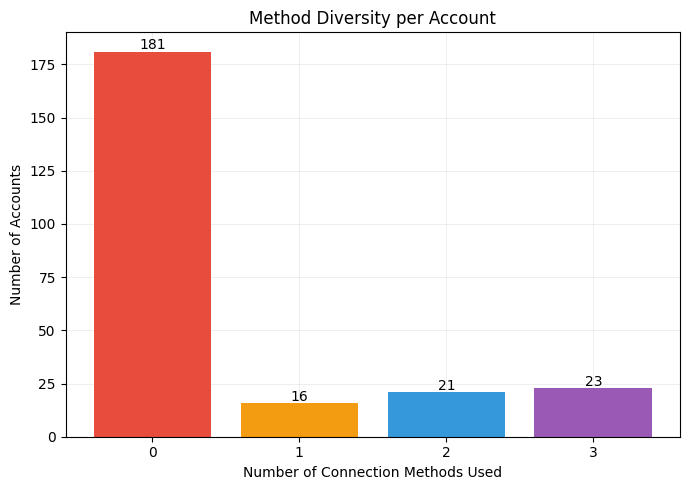

In [ ]:
# chart - method diversity distribution

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(diversity.index.astype(str), diversity.values, color=[COLOR_PASSIVE, COLOR_JOB, COLOR_MSG, COLOR_CV])

for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2,
           bar.get_height() + 1,
           int(bar.get_height()),
           ha='center', fontsize=10)

ax.set_axisbelow(True)
ax.grid(True, which='major', axis='both', linestyle='-', linewidth=0.5, alpha=0.3)

ax.set_xlabel('Number of Connection Methods Used')
ax.set_ylabel('Number of Accounts')
ax.set_title('Method Diversity per Account')
plt.tight_layout()
plt.show()

# 3.Credit Consumption

In [ ]:
# total credits by method

total_msg_credits = df['msg_credits'].sum()
total_job_credits = df['job_credits'].sum()
total_cv_credits = df['cv_credits'].sum()
total_credits_all = df['total_credits'].sum()

print(f"Message credits : {total_msg_credits:,} ({total_msg_credits/total_credits_all*100:.1f}%)")
print(f"Job Send credits : {total_job_credits:,} ({total_job_credits/total_credits_all*100:.1f}%)")
print(f"CV credits : {total_cv_credits:,} ({total_cv_credits/total_credits_all*100:.1f}%)")
print(f"Total credits : {total_credits_all:,}")

Message credits : 39,200 (1.4%)
Job Send credits : 89,900 (3.2%)
CV credits : 2,688,500 (95.4%)
Total credits : 2,817,600


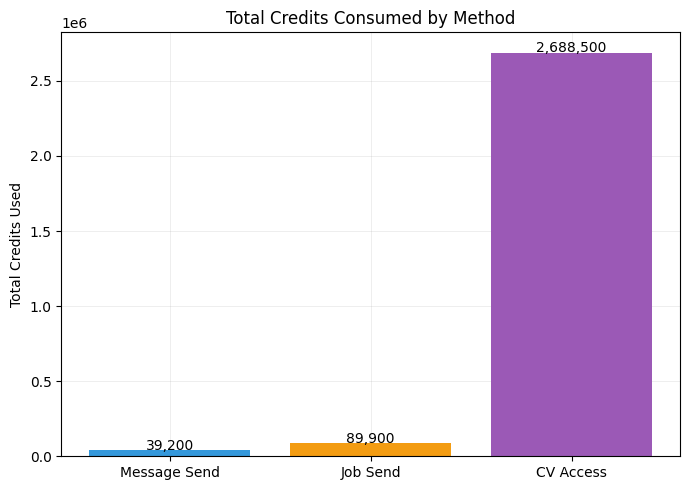

In [ ]:
methods = ['Message Send', 'Job Send', 'CV Access']
credits = [total_msg_credits, total_job_credits, total_cv_credits]
colors  = [COLOR_MSG, COLOR_JOB, COLOR_CV]

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(methods, credits, color=colors)

for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 500,
            f'{int(bar.get_height()):,}', ha='center', fontsize=10)

ax.set_axisbelow(True)
ax.grid(True, which='major', axis='both', linestyle='-', linewidth=0.5, alpha=0.3)

ax.set_ylabel('Total Credits Used')
ax.set_title('Total Credits Consumed by Method')
plt.tight_layout()
plt.show()

In [ ]:
credits_per_account = df.groupby('account_id')['total_credits'].sum().reset_index()
credits_per_account.columns = ['account_id', 'total_credits']

pd.set_option('display.float_format', '{:.2f}'.format)

print(credits_per_account['total_credits'].describe())

count       241.00
mean      11691.29
std       86084.51
min           0.00
25%           0.00
50%           0.00
75%           0.00
max     1250500.00
Name: total_credits, dtype: float64


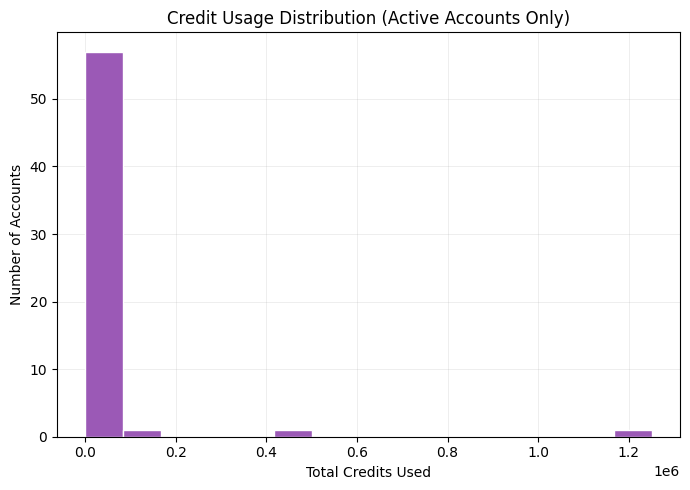

In [ ]:
# chart - distribution of credits per account (histogram)

active_credits = credits_per_account[credits_per_account['total_credits'] > 0]

fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(active_credits['total_credits'], bins=15, color=COLOR_CV, edgecolor='white')

ax.set_axisbelow(True)
ax.grid(True, which='major', axis='both', linestyle='-', linewidth=0.5, alpha=0.3)

ax.set_xlabel('Total Credits Used')
ax.set_ylabel('Number of Accounts')
ax.set_title('Credit Usage Distribution (Active Accounts Only)')
plt.tight_layout()
plt.show()

In [ ]:
# monthly credit consumption trend

monthly_credits = df.groupby('month_label')['total_credits'].sum().reindex(MONTH_ORDER)

print('Monthly total credits:')
print(monthly_credits)

Monthly total credits:
month_label
Nov 2014     526200
Dec 2014    1065700
Jan 2015    1225700
Name: total_credits, dtype: int64


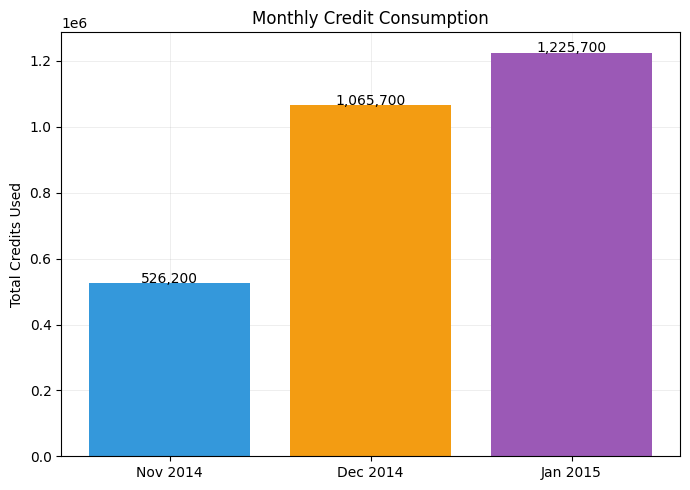

In [ ]:
# monthly credit trend

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(MONTH_ORDER, monthly_credits.values, color=[COLOR_MSG, COLOR_JOB, COLOR_CV])

for i, val in enumerate(monthly_credits.values):
    ax.text(i, val + 500, f'{int(val):,}', ha='center', fontsize=10)

ax.set_axisbelow(True)
ax.grid(True, which='major', axis='both', linestyle='-', linewidth=0.5, alpha=0.3)

ax.set_ylabel('Total Credits Used')
ax.set_title('Monthly Credit Consumption')
plt.tight_layout()
plt.show()

In [ ]:
# outlier detection

# flag accounts in top 5% of credit usage
active_credits = credits_per_account[credits_per_account['total_credits'] > 0]
threshold = active_credits['total_credits'].quantile(0.95)

outliers = active_credits[active_credits['total_credits'] >= threshold]
outliers = outliers.sort_values('total_credits', ascending=False)

print(f'Top 5% threshold : {threshold:,.0f} credits')
print(f'Top accounts by credit usage:')
print(outliers.head(10))

Top 5% threshold : 73,045 credits
Top accounts by credit usage:
     account_id  total_credits
239    88547883        1250500
198    81806477         450000
235    87683018          98600


In [ ]:
# what % of total credits do the top 10% of accounts consume?
top_10_pct = credits_per_account['total_credits'].quantile(0.90)
top_accounts = credits_per_account[credits_per_account['total_credits'] >= top_10_pct]

top_credits = top_accounts['total_credits'].sum()
total_credits_all = credits_per_account['total_credits'].sum()

print(f"Top 10% accounts consumed : {top_credits/total_credits_all*100:.1f}% of all credits")

# how many accounts make up 70%+ of credits?
sorted_accounts = credits_per_account.sort_values('total_credits', ascending=False)
sorted_accounts['cumulative_pct'] = sorted_accounts['total_credits'].cumsum() / total_credits_all * 100
print(sorted_accounts[['account_id', 'total_credits', 'cumulative_pct']].head(10))

Top 10% accounts consumed : 92.3% of all credits
     account_id  total_credits  cumulative_pct
239    88547883        1250500           44.38
198    81806477         450000           60.35
235    87683018          98600           63.85
205    83410767          71700           66.40
224    86472783          63700           68.66
233    87637168          58300           70.73
118    38573723          50000           72.50
203    82878850          42900           74.02
78       355167          41600           75.50
65         8345          40100           76.92


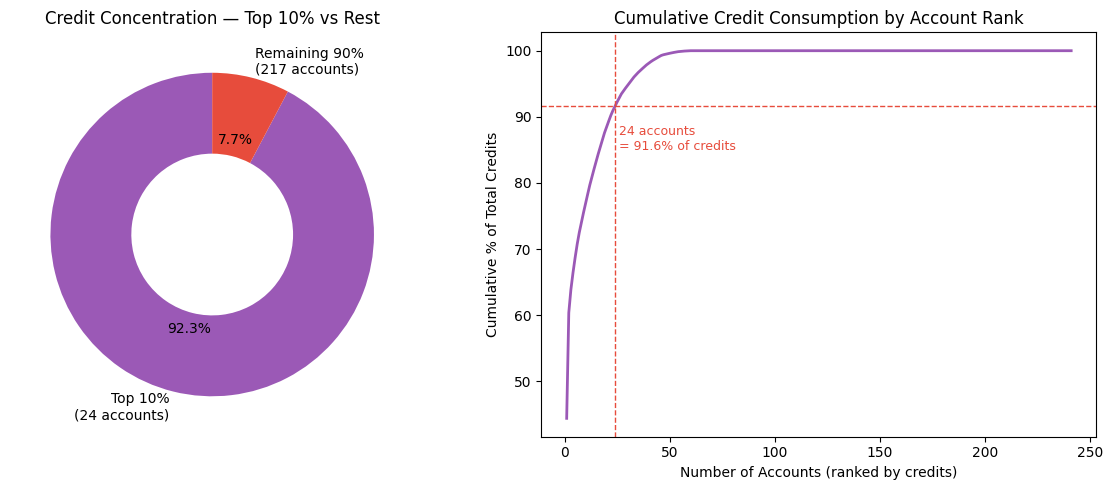

In [ ]:
# Chart — Credit concentration: top 10% vs rest
labels = ['Top 10%\n(24 accounts)', 'Remaining 90%\n(217 accounts)']
values = [top_credits, total_credits_all - top_credits]
colors = [COLOR_CV, COLOR_PASSIVE]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left — Donut chart
wedges, texts, autotexts = axes[0].pie(
    values,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops=dict(width=0.5)
)
axes[0].set_title('Credit Concentration — Top 10% vs Rest')

# Right — Cumulative credit % by account rank
axes[1].plot(
    range(1, len(sorted_accounts) + 1),
    sorted_accounts['cumulative_pct'],
    color=COLOR_CV,
    linewidth=2
)
axes[1].axhline(y=91.6, color=COLOR_PASSIVE, linestyle='--', linewidth=1)
axes[1].axvline(x=24,   color=COLOR_PASSIVE, linestyle='--', linewidth=1)
axes[1].text(26, 85, '24 accounts\n= 91.6% of credits', fontsize=9, color=COLOR_PASSIVE)

axes[1].set_xlabel('Number of Accounts (ranked by credits)')
axes[1].set_ylabel('Cumulative % of Total Credits')
axes[1].set_title('Cumulative Credit Consumption by Account Rank')

plt.tight_layout()
plt.show()

# 4.Account Segmentation

In [ ]:
active_credits = credits_per_account[credits_per_account['total_credits'] > 0]['total_credits']

print(f"50th percentile : {active_credits.quantile(0.50):,.0f} credits")
print(f"90th percentile : {active_credits.quantile(0.90):,.0f} credits")
print(f"Max             : {active_credits.max():,.0f} credits")

50th percentile : 11,850 credits
90th percentile : 50,830 credits
Max             : 1,250,500 credits


In [ ]:
# Segment accounts into tiers by credit usage

conditions = [
    credits_per_account['total_credits'] == 0,
    credits_per_account['total_credits'] <= credits_per_account['total_credits'][credits_per_account['total_credits'] > 0].quantile(0.50),
    credits_per_account['total_credits'] <= credits_per_account['total_credits'][credits_per_account['total_credits'] > 0].quantile(0.90),
]
choices = ['Passive', 'Light', 'Moderate']

credits_per_account['segment'] = np.select(conditions, choices, default='Heavy')

print(credits_per_account['segment'].value_counts())

segment
Passive     181
Light        30
Moderate     24
Heavy         6
Name: count, dtype: int64


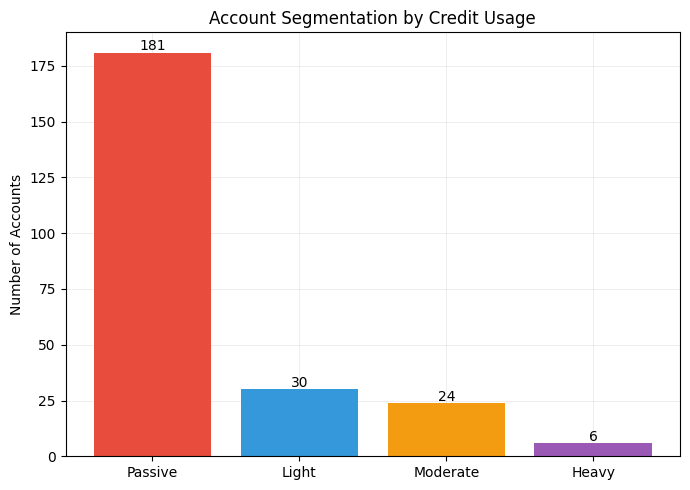

In [ ]:
segment_order  = ['Passive', 'Light', 'Moderate', 'Heavy']
segment_colors = ['#e74c3c', '#3498db', '#f39c12', '#9b59b6']
segment_counts = credits_per_account['segment'].value_counts().reindex(segment_order)

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(segment_order, segment_counts.values, color=segment_colors)

for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
            str(int(bar.get_height())), ha='center', fontsize=10)

ax.set_axisbelow(True)
ax.grid(True, which='major', axis='both', linestyle='-', linewidth=0.5, alpha=0.3)

ax.set_ylabel('Number of Accounts')
ax.set_title('Account Segmentation by Credit Usage')
plt.tight_layout()
plt.show()

In [ ]:
#  Profile each segment

segment_profile = credits_per_account.groupby('segment')['total_credits'].agg(
    accounts='count',
    total_credits='sum',
    avg_credits='mean',
    max_credits='max'
).reindex(segment_order)

segment_profile['share_of_total'] = segment_profile['total_credits'] / total_credits_all * 100

print(segment_profile.round(0))

          accounts  total_credits  avg_credits  max_credits  share_of_total
segment                                                                    
Passive        181              0         0.00            0            0.00
Light           30         147400      4913.00        11800            5.00
Moderate        24         677400     28225.00        50000           24.00
Heavy            6        1992800    332133.00      1250500           71.00


In [ ]:
# Job ad count vs credit usage

job_ads_per_account = df.groupby('account_id')['job_ad_id'].nunique().reset_index()
job_ads_per_account.columns = ['account_id', 'unique_job_ads']

credits_per_account = credits_per_account.merge(job_ads_per_account, on='account_id', how='left')

correlation = credits_per_account['unique_job_ads'].corr(credits_per_account['total_credits'])
print(f'Correlation (job ads vs credits used): {correlation:.2f}')

Correlation (job ads vs credits used): 0.22


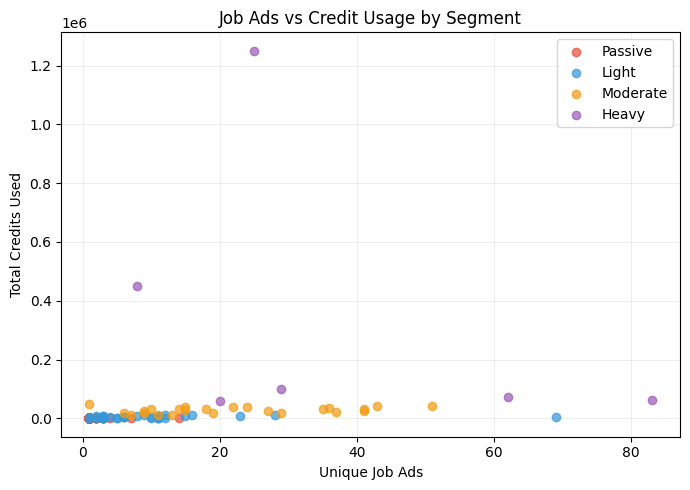

In [ ]:
# chart - Scatter plot

fig, ax = plt.subplots(figsize=(7, 5))

for seg, color in zip(segment_order, segment_colors):
    subset = credits_per_account[credits_per_account['segment'] == seg]
    ax.scatter(subset['unique_job_ads'], subset['total_credits'],
               label=seg, color=color, alpha=0.7)

ax.set_axisbelow(True)
ax.grid(True, which='major', axis='both', linestyle='-', linewidth=0.5, alpha=0.3)

ax.set_xlabel('Unique Job Ads')
ax.set_ylabel('Total Credits Used')
ax.set_title('Job Ads vs Credit Usage by Segment')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Job ads for the top credit consuming account
top_account_id = credits_per_account.sort_values(
    'total_credits', ascending=False
).iloc[0]['account_id']

top_account_jobs = credits_per_account[
    credits_per_account['account_id'] == top_account_id
][['account_id', 'total_credits', 'unique_job_ads']]

top_account_pct = (
    top_account_jobs['total_credits'].values[0] / total_credits_all * 100
)

print(f'Top account ID      : {int(top_account_id)}')
print(f'Unique job ads      : {int(top_account_jobs["unique_job_ads"].values[0])}')
print(f'Total credits used  : {int(top_account_jobs["total_credits"].values[0]):,}')
print(f'Share of all credits: {top_account_pct:.1f}%')

Top account ID      : 88547883
Unique job ads      : 25
Total credits used  : 1,250,500
Share of all credits: 44.4%


# 5.User Behaviour Within Accounts

In [ ]:
# Users per account distribution

users_per_account = df.groupby('account_id')['user_id'].nunique().reset_index()
users_per_account.columns = ['account_id', 'unique_users']

print(users_per_account['unique_users'].describe())
print(f'\nAccounts with only 1 user : {(users_per_account["unique_users"] == 1).sum()}')
print(f'Accounts with 2+ users    : {(users_per_account["unique_users"] > 1).sum()}')

count   241.00
mean      2.20
std       3.93
min       1.00
25%       1.00
50%       1.00
75%       1.00
max      40.00
Name: unique_users, dtype: float64

Accounts with only 1 user : 186
Accounts with 2+ users    : 55


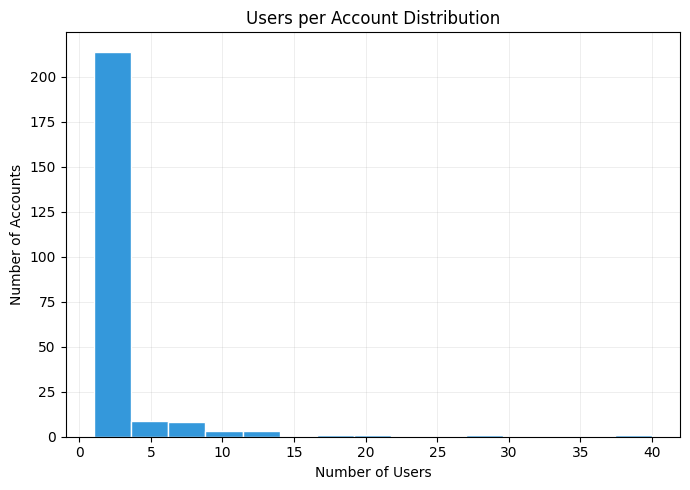

In [ ]:
# chart - histogram of users per account

fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(users_per_account['unique_users'], bins=15, color=COLOR_MSG, edgecolor='white')

ax.set_axisbelow(True)
ax.grid(True, which='major', axis='both', linestyle='-', linewidth=0.5, alpha=0.3)

ax.set_xlabel('Number of Users')
ax.set_ylabel('Number of Accounts')
ax.set_title('Users per Account Distribution')
plt.tight_layout()
plt.show()

In [ ]:
# credit concentration within accounts

credits_per_user = df.groupby(['account_id', 'user_id'])['total_credits'].sum().reset_index()
credits_per_user.columns = ['account_id', 'user_id', 'user_credits']

account_totals = credits_per_user.groupby('account_id')['user_credits'].sum().reset_index()
account_totals.columns = ['account_id', 'account_total']

credits_per_user = credits_per_user.merge(account_totals, on='account_id')
credits_per_user['user_share'] = credits_per_user['user_credits'] / credits_per_user['account_total']

# Among multi-user accounts only
multi_user_accounts = users_per_account[users_per_account['unique_users'] > 1]['account_id']
multi_user_top = credits_per_user[credits_per_user['account_id'].isin(multi_user_accounts)]

top_user_share = multi_user_top.groupby('account_id')['user_share'].max()
print('Top user credit share within multi-user accounts:')
print(top_user_share.describe().round(2))

Top user credit share within multi-user accounts:
count   47.00
mean     0.71
std      0.25
min      0.28
25%      0.51
50%      0.70
75%      1.00
max      1.00
Name: user_share, dtype: float64


In [ ]:
# top 10 most active users

top_users = credits_per_user.sort_values('user_credits', ascending=False).head(10)
top_users = top_users[['account_id', 'user_id', 'user_credits']].reset_index(drop=True)

print('Top 10 users by credit consumption:')
print(top_users)

Top 10 users by credit consumption:
   account_id   user_id  user_credits
0    88547883    801200        350000
1    88547883    188848        300400
2    88547883    188843        250000
3    88547883    188800        200000
4    81806477  81806477        200000
5    81806477    808172        150000
6    87637168    808718         50600
7    88547883    188837         50100
8    88547883    808614         50000
9    88547883    188784         50000


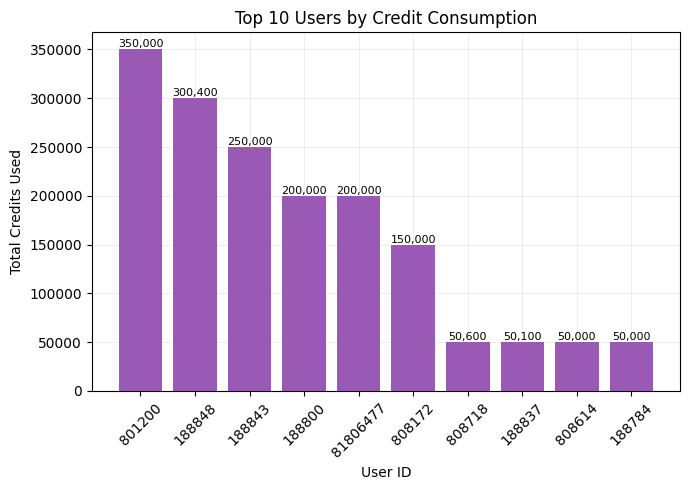

In [ ]:
# chart - Bar chart of top 10 users

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(top_users['user_id'].astype(str), top_users['user_credits'], color=COLOR_CV)

for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2000,
            f'{int(bar.get_height()):,}', ha='center', fontsize=8)

ax.set_axisbelow(True)
ax.grid(True, which='major', axis='both', linestyle='-', linewidth=0.5, alpha=0.3)

ax.set_xlabel('User ID')
ax.set_ylabel('Total Credits Used')
ax.set_title('Top 10 Users by Credit Consumption')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 6.Monthly Trend & Adoption

In [ ]:
# Monthly active accounts and users

monthly_active = df[df['connection_made'] == 1].groupby('month_label').agg(
    active_accounts=('account_id', 'nunique'),
    active_users=('user_id', 'nunique')
).reindex(MONTH_ORDER)

print(monthly_active)

             active_accounts  active_users
month_label                               
Nov 2014                  33            70
Dec 2014                  46            93
Jan 2015                  51           102


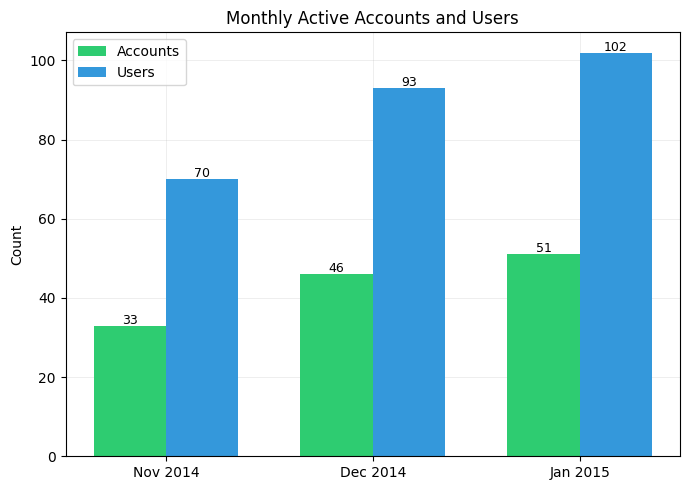

In [ ]:
# chart - side by side bar chart

x = range(len(MONTH_ORDER))
width = 0.35

fig, ax = plt.subplots(figsize=(7, 5))
bars1 = ax.bar([i - width/2 for i in x], monthly_active['active_accounts'], width, label='Accounts', color=COLOR_ACTIVE)
bars2 = ax.bar([i + width/2 for i in x], monthly_active['active_users'],   width, label='Users',    color=COLOR_MSG)

for bar in bars1 + bars2:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            str(int(bar.get_height())), ha='center', fontsize=9)

ax.set_axisbelow(True)
ax.grid(True, which='major', axis='both', linestyle='-', linewidth=0.5, alpha=0.3)

ax.set_xticks(list(x))
ax.set_xticklabels(MONTH_ORDER)
ax.set_ylabel('Count')
ax.set_title('Monthly Active Accounts and Users')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
#  Monthly connections by type

monthly_connections = df.groupby('month_label')[['msg_sends', 'job_sends', 'cv_accessed']].sum().reindex(MONTH_ORDER)

print(monthly_connections)

             msg_sends  job_sends  cv_accessed
month_label                                   
Nov 2014            22        313          981
Dec 2014           106        260         2037
Jan 2015            68        326         2359


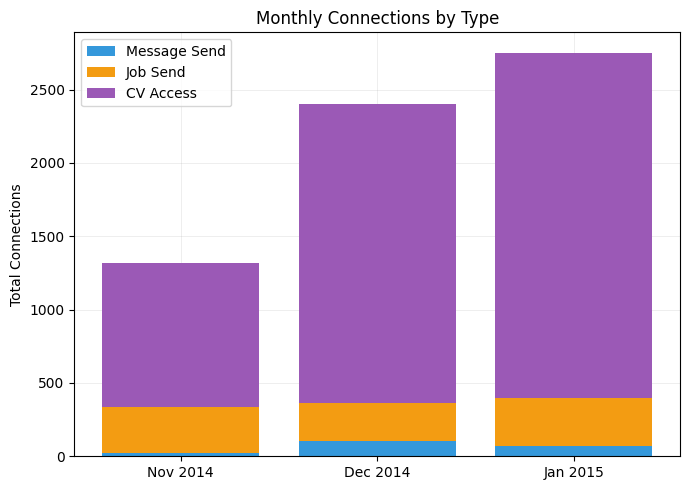

In [ ]:
 # chart - stacked bar chart

fig, ax = plt.subplots(figsize=(7, 5))

ax.bar(MONTH_ORDER, monthly_connections['msg_sends'],  label='Message Send', color=COLOR_MSG, bottom=0)
ax.bar(MONTH_ORDER, monthly_connections['job_sends'],  label='Job Send',     color=COLOR_JOB,
       bottom=monthly_connections['msg_sends'])
ax.bar(MONTH_ORDER, monthly_connections['cv_accessed'], label='CV Access',   color=COLOR_CV,
       bottom=monthly_connections['msg_sends'] + monthly_connections['job_sends'])

ax.set_axisbelow(True)
ax.grid(True, which='major', axis='both', linestyle='-', linewidth=0.5, alpha=0.3)

ax.set_ylabel('Total Connections')
ax.set_title('Monthly Connections by Type')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Average credits per active account per month

monthly_account_credits = df[df['connection_made'] == 1].groupby(['month_label', 'account_id'])['total_credits'].sum().reset_index()

avg_credits_per_month = monthly_account_credits.groupby('month_label')['total_credits'].mean().reindex(MONTH_ORDER)

print('Avg credits per active account per month:')
print(avg_credits_per_month.round(0))

Avg credits per active account per month:
month_label
Nov 2014   15945.00
Dec 2014   23167.00
Jan 2015   24033.00
Name: total_credits, dtype: float64


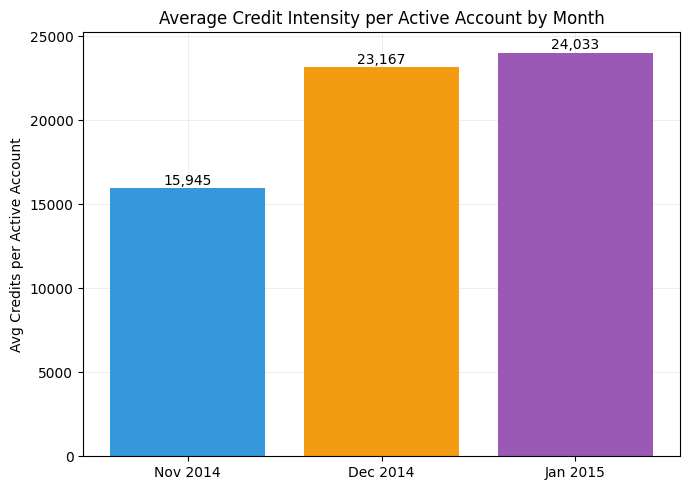

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(MONTH_ORDER, avg_credits_per_month.values, color=[COLOR_MSG, COLOR_JOB, COLOR_CV])

for i, val in enumerate(avg_credits_per_month.values):
    ax.text(i, val + 200, f'{int(val):,}', ha='center', fontsize=10)

ax.set_axisbelow(True)
ax.grid(True, which='major', axis='both', linestyle='-', linewidth=0.5, alpha=0.3)

ax.set_ylabel('Avg Credits per Active Account')
ax.set_title('Average Credit Intensity per Active Account by Month')
plt.tight_layout()
plt.show()

In [ ]:
print(f"Avg connections per account : {df.groupby('account_id')['total_connections'].sum().mean():.1f}")
print(f"Avg credits per account     : {df.groupby('account_id')['total_credits'].sum().mean():.1f}")
print(f"Avg job ads per account     : {df.groupby('account_id')['job_ad_id'].nunique().mean():.1f}")

Avg connections per account : 26.9
Avg credits per account     : 11691.3
Avg job ads per account     : 5.3


In [ ]:
active_ids = df[df['connection_made'] == 1]['account_id'].unique()
active_df  = df[df['account_id'].isin(active_ids)]

print(f"Avg connections (active) : {active_df.groupby('account_id')['total_connections'].sum().mean():.1f}")
print(f"Avg credits (active)     : {active_df.groupby('account_id')['total_credits'].sum().mean():.1f}")
print(f"Avg job ads (active)     : {active_df.groupby('account_id')['job_ad_id'].nunique().mean():.1f}")

Avg connections (active) : 107.9
Avg credits (active)     : 46960.0
Avg job ads (active)     : 17.8


# 7.Risk Signals

In [ ]:
# Credit concentration risk

# What share of credits do the top 10% of accounts consume
top_10_pct = credits_per_account.nlargest(int(len(credits_per_account) * 0.10), 'total_credits')

top_10_share = top_10_pct['total_credits'].sum() / total_credits_all * 100
top_10_count = len(top_10_pct)

print(f'Top 10% accounts ({top_10_count} accounts) consumed {top_10_share:.1f}% of all credits')
print(f'Remaining 90%   ({241 - top_10_count} accounts) consumed {100 - top_10_share:.1f}% of all credits')

Top 10% accounts (24 accounts) consumed 91.6% of all credits
Remaining 90%   (217 accounts) consumed 8.4% of all credits


In [ ]:
#  Passive account rate

passive_count  = (credits_per_account['total_credits'] == 0).sum()
active_count   = (credits_per_account['total_credits'] > 0).sum()
passive_rate   = passive_count / len(credits_per_account) * 100

print(f'Passive accounts : {passive_count} ({passive_rate:.1f}%)')
print(f'Active accounts  : {active_count} ({100 - passive_rate:.1f}%)')
print(f'\nOf active accounts:')
print(credits_per_account[credits_per_account['total_credits'] > 0]['total_credits'].describe().round(0))

Passive accounts : 181 (75.1%)
Active accounts  : 60 (24.9%)

Of active accounts:
count        60.00
mean      46960.00
std      168702.00
min         500.00
25%        5000.00
50%       11850.00
75%       32000.00
max     1250500.00
Name: total_credits, dtype: float64


In [ ]:
# CV Access outlier risk

cv_share_of_credits      = total_cv_credits / total_credits_all * 100
cv_share_of_connections  = df['cv_accessed'].sum() / (df['msg_sends'].sum() + df['job_sends'].sum() + df['cv_accessed'].sum()) * 100

print(f'CV Access share of total credits     : {cv_share_of_credits:.1f}%')
print(f'CV Access share of total connections : {cv_share_of_connections:.1f}%')
print(f'\nIf CV Access were capped or removed, credits saved : {total_cv_credits:,}')
print(f'That is {total_cv_credits/total_credits_all*100:.1f}% of all credit spend')

CV Access share of total credits     : 95.4%
CV Access share of total connections : 83.1%

If CV Access were capped or removed, credits saved : 2,688,500
That is 95.4% of all credit spend


In [ ]:
# Single user dominance risk

single_user_accounts = (users_per_account['unique_users'] == 1).sum()
single_user_pct      = single_user_accounts / len(users_per_account) * 100

print(f'Single-user accounts : {single_user_accounts} ({single_user_pct:.1f}%)')
print(f'Multi-user accounts  : {len(users_per_account) - single_user_accounts} ({100 - single_user_pct:.1f}%)')

# Within active accounts only
active_ids             = credits_per_account[credits_per_account['total_credits'] > 0]['account_id']
active_user_counts     = users_per_account[users_per_account['account_id'].isin(active_ids)]
active_single_user_pct = (active_user_counts['unique_users'] == 1).sum() / len(active_user_counts) * 100

print(f'\nAmong active accounts only:')
print(f'Single-user : {(active_user_counts["unique_users"] == 1).sum()} ({active_single_user_pct:.1f}%)')
print(f'Multi-user  : {(active_user_counts["unique_users"] > 1).sum()} ({100 - active_single_user_pct:.1f}%)')

Single-user accounts : 186 (77.2%)
Multi-user accounts  : 55 (22.8%)

Among active accounts only:
Single-user : 13 (21.7%)
Multi-user  : 47 (78.3%)


In [ ]:
#  Zero session accounts

zero_session = df[df['sessions'] == 0]

print(f'Rows with zero sessions      : {len(zero_session)}')
print(f'Unique accounts in zero rows : {zero_session["account_id"].nunique()}')
print(f'Credits consumed in these rows: {zero_session["total_credits"].sum():,}')

Rows with zero sessions      : 0
Unique accounts in zero rows : 0
Credits consumed in these rows: 0


In [ ]:
# Risk summary table

risks = {
    'Credit concentration (top 10% accounts)' : f'{top_10_share:.1f}% of all credits',
    'Passive account rate'                     : f'{passive_rate:.1f}% never connected',
    'CV Access share of credits'               : f'{cv_share_of_credits:.1f}% of total spend',
    'Single-user account rate'                 : f'{single_user_pct:.1f}% of all accounts',
}

print('--- Risk Signal Summary ---')
for risk, finding in risks.items():
    print(f'{risk:<45} : {finding}')

--- Risk Signal Summary ---
Credit concentration (top 10% accounts)       : 91.6% of all credits
Passive account rate                          : 75.1% never connected
CV Access share of credits                    : 95.4% of total spend
Single-user account rate                      : 77.2% of all accounts


In [ ]:
# Install required libraries
!pip install gspread gspread-dataframe --quiet

# Authenticate
from google.colab import auth
auth.authenticate_user()

import gspread
from gspread_dataframe import set_with_dataframe
from google.auth import default

creds, _ = default()
gc = gspread.authorize(creds)

In [ ]:
# Create workbook
wb = gc.create('Candidate Search Tool Analytics — Dashboard Data')

# Sheet 1 — Main data
ws1 = wb.sheet1
ws1.update_title('main')
set_with_dataframe(ws1, df)

# Sheet 2 — Credits per account with segment
ws2 = wb.add_worksheet(title='credits_per_account', rows=300, cols=10)
set_with_dataframe(ws2, credits_per_account)

# Sheet 3 — Monthly summary
monthly_summary = df.groupby('month_label').agg(
    total_credits=('total_credits', 'sum'),
    active_accounts=('account_id', 'nunique'),
    active_users=('user_id', 'nunique'),
    msg_sends=('msg_sends', 'sum'),
    job_sends=('job_sends', 'sum'),
    cv_accessed=('cv_accessed', 'sum')
).reindex(MONTH_ORDER).reset_index()

# Add month order column for correct sorting
monthly_summary['month_order'] = [1, 2, 3]

ws3 = wb.add_worksheet(title='monthly_summary', rows=10, cols=10)
set_with_dataframe(ws3, monthly_summary)

# Sheet 4 — Credits per user
ws4 = wb.add_worksheet(title='credits_per_user', rows=600, cols=10)
set_with_dataframe(ws4, credits_per_user)

# Sheet 5 — Method summary (for donut chart)
method_summary = pd.DataFrame({
    'method'      : ['Message Send', 'Job Send', 'CV Access'],
    'credits'     : [total_msg_credits, total_job_credits, total_cv_credits],
    'connections' : [df['msg_sends'].sum(), df['job_sends'].sum(), df['cv_accessed'].sum()]
})

ws5 = wb.add_worksheet(title='method_summary', rows=10, cols=5)
set_with_dataframe(ws5, method_summary)

print(f'Done. Open your workbook here:')
print(wb.url)

Done. Open your workbook here:
https://docs.google.com/spreadsheets/d/15U4LsI24Od3wCTxJqKPFt8OZkhAqJjtPz2QucOU36zs
